# Task 3: Machine Learning with Linear Regression
## Predicting the compressive strength of concrete from its recipe and age
IU · DLBDSIDS01-02 Introduction to Data Science · Oral Assignment

**Problem.** Concrete is accepted on site only after test cylinders are crushed, usually at **28 days**. Can a linear regression model estimate the strength earlier, from the mix recipe and the age?

**Data.** One dataset: 1,030 laboratory tests of concrete (Yeh, 1998). 8 input features (7 ingredients in kg per m³ plus age in days); target = compressive strength in MPa.

| Task 3 asks for … | Where in this notebook |
|---|---|
| 1. ML paradigms and which one linear regression belongs to | Part 1 |
| 2. How linear regression works | Part 2 |
| 3. Application to a real problem, why LR fits, visual results and analysis | Part 3 (statistical analysis first, then the model) |

# Part 1: Machine-learning paradigms

| Paradigm | Training data | Goal | Typical tasks |
|---|---|---|---|
| **Supervised** | Every record has a known answer (label) | Learn the mapping input → label to predict new cases | Regression (continuous label), classification (categories) |
| **Unsupervised** | No labels | Find hidden structure in the data | Clustering (e.g. k-means), dimensionality reduction |
| **Semi-supervised** | A few labelled and many unlabelled records | Use the unlabelled data to improve a model when labelling is expensive | Self-training, label propagation |

**Linear regression is supervised learning, regression task.** Every concrete test in the data has a measured strength (the label), the label is a continuous number in MPa, and the model learns the input → strength relationship from these labelled examples to predict the strength of new mixes.

# Part 2: How linear regression works

**1. The model.** The target $y$ is written as a weighted sum of the features $x_1 … x_m$ (course-book notation):

$$y = w_0 + w_1x_1 + w_2x_2 + … + w_mx_m + \varepsilon$$

$w_0$ is the bias (intercept), $w_1 … w_m$ are the weights and $\varepsilon$ is the error the features cannot explain. A weight says how much $y$ changes when that feature rises by one unit **while the other features stay the same**.

**2. Learning = choosing the weights.** Ordinary least squares picks the weights that minimise the mean squared error on the training data, $\text{MSE} = \frac{1}{n}\sum_i (d_i - y_i)^2$ with prediction $d_i$. The minimum has a closed-form solution, so training is fast and always gives the same answer.

**3. Assumptions** (checked in Part 3.7): the relationship is linear, errors are independent, errors have constant spread, and errors are roughly normal.

**4. Hyperparameters used in Part 3.6.**
* **Feature transformation:** a feature can be transformed (e.g. $\log(\text{age})$) when its effect is curved.
* **Polynomial degree:** adding squared and interaction terms ($x_1^2$, $x_1x_2$, …) lets the model bend. It is still *linear regression*, because it stays linear in the weights.
* **Ridge penalty $\alpha$:** minimise $\text{MSE} + \alpha\sum_j w_j^2$. A larger $\alpha$ keeps the weights small and protects against overfitting when there are many terms.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import sklearn
import statsmodels
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42

# Folders: the dataset is in data/ (identical copy in src/)
PROJECT_DIR = Path.cwd()
DATA_DIR = next((PROJECT_DIR / d for d in ("data", "src") if (PROJECT_DIR / d / "concrete.csv").exists()), PROJECT_DIR / "data")
FIG_DIR, OUT_DIR = PROJECT_DIR / "figures", PROJECT_DIR / "outputs"
FIG_DIR.mkdir(exist_ok=True); OUT_DIR.mkdir(exist_ok=True)

# One simple, colour-blind-safe plot style for every figure
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8c8c8c"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 11,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "figure.facecolor": "white", "axes.facecolor": "white",
})
def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()

print(f"numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__} | "
      f"scikit-learn {sklearn.__version__} | statsmodels {statsmodels.__version__} | matplotlib {matplotlib.__version__}")
print("Data folder:", DATA_DIR.name + "/")

numpy 2.5.4 | pandas 3.1.1 | scipy 1.18.1 | scikit-learn 1.9.1 | statsmodels 0.15.0 | matplotlib 3.11.2
Data folder: data/


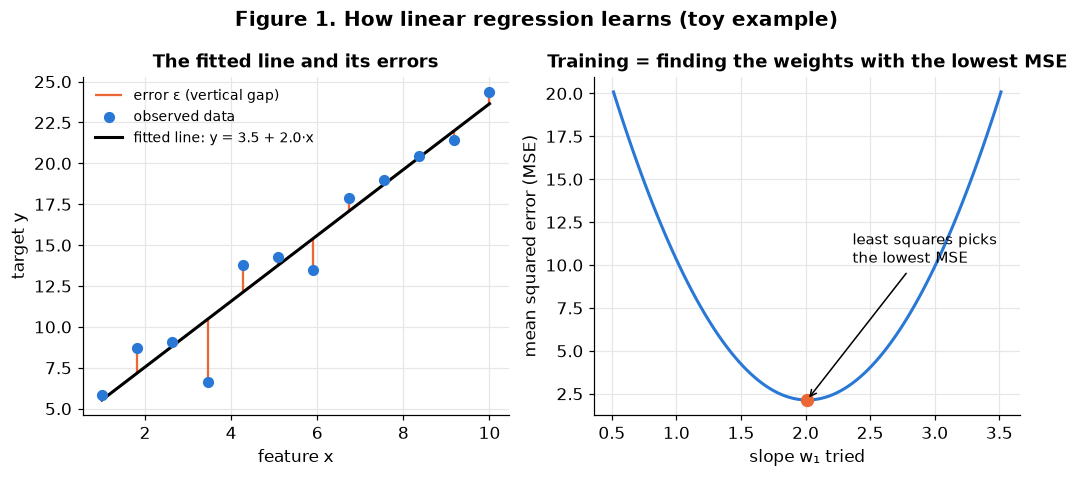

In [2]:
# Toy example (made-up numbers, NOT the concrete data): what "least squares" means
rng = np.random.default_rng(1)
x_toy = np.linspace(1, 10, 12)
y_toy = 3 + 2 * x_toy + rng.normal(0, 2.5, x_toy.size)
w1_hat, w0_hat = np.polyfit(x_toy, y_toy, 1)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.vlines(x_toy, y_toy, w0_hat + w1_hat * x_toy, color=ORANGE, lw=1.5, label="error ε (vertical gap)")
a1.scatter(x_toy, y_toy, color=BLUE, s=40, zorder=3, label="observed data")
a1.plot(x_toy, w0_hat + w1_hat * x_toy, color="black", lw=2, label=f"fitted line: y = {w0_hat:.1f} + {w1_hat:.1f}·x")
a1.set(xlabel="feature x", ylabel="target y", title="The fitted line and its errors")
a1.legend(frameon=False, fontsize=9)

slopes = np.linspace(w1_hat - 1.5, w1_hat + 1.5, 100)
mse = [np.mean((y_toy - (y_toy.mean() - s * x_toy.mean() + s * x_toy)) ** 2) for s in slopes]
a2.plot(slopes, mse, color=BLUE, lw=2)
a2.scatter([w1_hat], [min(mse)], color=ORANGE, s=60, zorder=3)
a2.annotate("least squares picks\nthe lowest MSE", (w1_hat, min(mse)), xytext=(w1_hat + 0.35, min(mse) + 8),
            arrowprops=dict(arrowstyle="->", color="black"), fontsize=10)
a2.set(xlabel="slope w₁ tried", ylabel="mean squared error (MSE)", title="Training = finding the weights with the lowest MSE")
fig.suptitle("Figure 1. How linear regression learns (toy example)", fontweight="bold", y=1.03)
save(fig, "fig01_how_linear_regression_learns")

# Part 3: Application, predicting concrete strength

## 3.1 The business problem and why linear regression fits it
* **Problem.** Ready-mixed concrete is accepted on the basis of cylinders that are cured and crushed at an age set in the specification, **usually 28 days** (NRMCA, CIP 9). Until then, a weak mix may already be built into a structure. An early estimate from the recipe helps engineers plan mixes and spot risky batches.
* **Sustainability angle.** Cement production causes about **8 % of global CO₂ emissions** (Chatham House, 2018). Replacing part of the cement with blast-furnace slag or fly ash cuts emissions, so engineers need to know how these ingredients change strength.
* **Analytical question.** How accurately can linear regression predict compressive strength (MPa) from the 8 recipe and age variables, and how does each ingredient change strength?
* **Why linear regression.**
  1. Labelled data with a continuous target → supervised regression.
  2. Weights are directly interpretable ("+1 kg of cement → +x MPa"), so engineers can check them against known physics (more water → weaker concrete).
  3. With 8 features and about 1,000 tests there is plenty of data per weight. Training is instant and reproducible.
* **How success is judged.** The model must clearly beat the naive benchmark that always predicts the average strength. Errors are reported in MPa (MAE, RMSE), plus R² and MAPE, the course-book metrics.

## 3.2 The data
Source: Yeh, I-C. (1998), *Cement and Concrete Research* 28(12), 1797–1808, UCI Machine Learning Repository (CC BY 4.0). The 1,030 tests were compiled from 17 different sources. File `concrete.csv`, exported unchanged from the R package *AppliedPredictiveModeling* (Kuhn & Johnson, 2013).

In [3]:
df_raw = pd.read_csv(DATA_DIR / "concrete.csv")
TARGET = "CompressiveStrength"
FEATURES = ["Cement", "BlastFurnaceSlag", "FlyAsh", "Water", "Superplasticizer", "CoarseAggregate", "FineAggregate", "Age"]
INGREDIENTS = FEATURES[:-1]
UNITS = {c: "kg/m³" for c in INGREDIENTS} | {"Age": "days", TARGET: "MPa"}

data_dictionary = pd.DataFrame({
    "variable": FEATURES + [TARGET],
    "role": ["feature"] * 8 + ["target"],
    "unit": [UNITS[c] for c in FEATURES + [TARGET]],
    "meaning": ["Portland cement (the binder)", "Blast-furnace slag (cement replacement, by-product of steel making)",
                "Fly ash (cement replacement, by-product of coal power plants)", "Mixing water",
                "Superplasticizer (chemical that keeps the mix workable with less water)", "Coarse aggregate (gravel)",
                "Fine aggregate (sand)", "Age of the concrete when it was crushed",
                "Load at which the cylinder broke (higher = stronger)"],
})
print(f"{df_raw.shape[0]} rows × {df_raw.shape[1]} columns")
display(data_dictionary)
display(df_raw.head())

1030 rows × 9 columns


,variable,role,unit,meaning
0,Cement,feature,kg/m³,Portland cement (the binder)
1,BlastFurnaceSlag,feature,kg/m³,"Blast-furnace slag (cement replacement, by-pro..."
2,FlyAsh,feature,kg/m³,"Fly ash (cement replacement, by-product of coa..."
3,Water,feature,kg/m³,Mixing water
4,Superplasticizer,feature,kg/m³,Superplasticizer (chemical that keeps the mix ...
5,CoarseAggregate,feature,kg/m³,Coarse aggregate (gravel)
6,FineAggregate,feature,kg/m³,Fine aggregate (sand)
7,Age,feature,days,Age of the concrete when it was crushed
8,CompressiveStrength,target,MPa,Load at which the cylinder broke (higher = str...


,Cement,BlastFurnaceSlag,FlyAsh,Water,Superplasticizer,CoarseAggregate,FineAggregate,Age,CompressiveStrength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


## 3.3 Statistical analysis (before any model is trained)
This section only **describes** the data. Nothing here is fitted or learned. Every learned step (scaling, weights, hyperparameters) uses the training set only, after the split in 3.4. Patterns found here are hypotheses that Part 3.6 tests with cross-validation.

### 3.3.1 Data quality
The checks follow the course book's data-quality characteristics.

In [4]:
n_dup = int(df_raw.duplicated().sum())
quality = pd.DataFrame([
    ["Completeness", "missing values", int(df_raw.isna().sum().sum())],
    ["Accuracy", "negative or impossible values (amount < 0, age ≤ 0, strength ≤ 0)",
     int((df_raw[INGREDIENTS] < 0).sum().sum() + (df_raw["Age"] <= 0).sum() + (df_raw[TARGET] <= 0).sum())],
    ["Consistency", "exact duplicate rows (same recipe, same age, same strength)", n_dup],
    ["Relevance", "features without a physical link to strength", 0],
], columns=["dimension", "check", "count"])
display(quality)

zeros = (df_raw[FEATURES] == 0).sum()
print("Rows with value 0 per feature:\n" + zeros[zeros > 0].to_string())

df = df_raw.drop_duplicates().reset_index(drop=True)
print(f"\nRemoved {n_dup} exact duplicate rows → {len(df)} rows remain.")

,dimension,check,count
0,Completeness,missing values,0
1,Accuracy,"negative or impossible values (amount < 0, age...",0
2,Consistency,"exact duplicate rows (same recipe, same age, s...",25
3,Relevance,features without a physical link to strength,0


Rows with value 0 per feature:
BlastFurnaceSlag    471
FlyAsh              566
Superplasticizer    379

Removed 25 exact duplicate rows → 1005 rows remain.


**Findings**
* **No missing values and no impossible values.**
* **25 exact duplicate rows** are removed. A duplicate could otherwise end up in both the training and the test set, so the model would be tested on data it has already seen.
* **The zeros are true zeros, not missing data.** A mix without fly ash really contains 0 kg of fly ash, so the zeros stay.

### 3.3.2 Descriptive statistics

In [5]:
desc = pd.DataFrame({
    "mean": df.mean(), "median": df.median(), "mode": df.mode().iloc[0], "std": df.std(), "variance": df.var(),
    "min": df.min(), "max": df.max(), "range": df.max() - df.min(), "skewness": df.skew(),
}).round(2)
desc.insert(0, "unit", [UNITS[c] for c in desc.index])
desc.to_csv(OUT_DIR / "descriptive_statistics.csv")
display(desc)

,unit,mean,median,mode,std,variance,min,max,range,skewness
Cement,kg/m³,278.63,265.0,251.40,104.34,10887.72,102.00,540.0,438.00,0.56
BlastFurnaceSlag,kg/m³,72.04,20.0,0.00,86.17,7425.41,0.00,359.4,359.40,0.86
FlyAsh,kg/m³,55.54,0.0,0.00,64.21,4122.66,0.00,200.1,200.10,0.50
Water,kg/m³,182.08,185.7,192.00,21.34,455.37,121.80,247.0,125.20,0.03
Superplasticizer,kg/m³,6.03,6.1,0.00,5.92,35.05,0.00,32.2,32.20,0.98
CoarseAggregate,kg/m³,974.38,968.0,932.00,77.58,6018.60,801.00,1145.0,344.00,-0.07
FineAggregate,kg/m³,772.69,780.0,594.00,80.34,6454.59,594.00,992.6,398.60,-0.25
Age,days,45.86,28.0,28.00,63.73,4062.11,1.00,365.0,364.00,3.25
CompressiveStrength,MPa,35.25,33.8,23.52,16.28,265.20,2.33,82.6,80.27,0.40


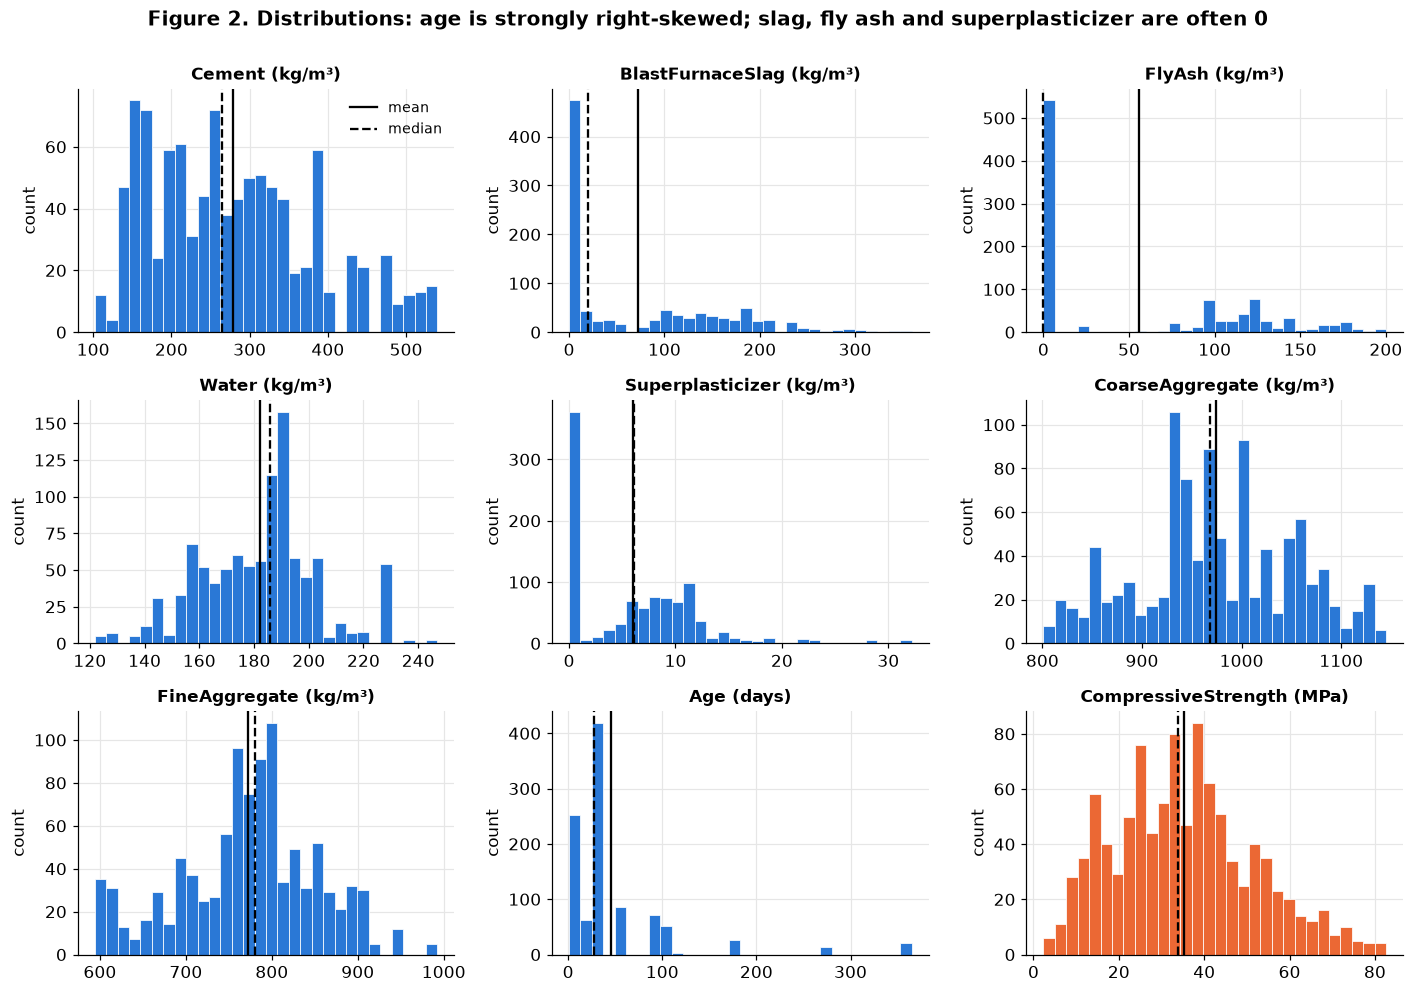

In [6]:
labels = {c: f"{c} ({UNITS[c]})" for c in FEATURES + [TARGET]}
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, col in zip(axes.ravel(), FEATURES + [TARGET]):
    color = ORANGE if col == TARGET else BLUE
    ax.hist(df[col], bins=30, color=color, edgecolor="white", linewidth=0.5)
    ax.axvline(df[col].mean(), color="black", lw=1.5, label="mean")
    ax.axvline(df[col].median(), color="black", lw=1.5, ls="--", label="median")
    ax.set_title(labels[col], fontsize=11)
    ax.set_ylabel("count")
axes[0, 0].legend(frameon=False, fontsize=9)
fig.suptitle("Figure 2. Distributions: age is strongly right-skewed; slag, fly ash and superplasticizer are often 0",
             fontweight="bold", y=1.0)
fig.tight_layout()
save(fig, "fig02_distributions")

**Reading the table and Figure 2**
* **Strength (orange)** ranges from about 2 to 83 MPa (mean ≈ 35.3, SD ≈ 16.3). It is only slightly right-skewed (skewness ≈ 0.4), so the target needs no transformation.
* **Age** is the most skewed feature (skewness ≈ 3.3). Most cylinders were crushed at 28 days (the mode), and few were tested at 180–365 days. The model will therefore see little data for very old concrete.
* **Slag, fly ash and superplasticizer** have a large spike at 0 (mixes without that ingredient). Water and the aggregates are roughly symmetric.

### 3.3.3 Outliers (IQR rule)

,lower fence,upper fence,outliers (n),outliers (%)
BlastFurnaceSlag,-213.8,356.2,2,0.2
Water,127.1,232.4,15,1.5
Superplasticizer,-15.0,25.0,10,1.0
FineAggregate,577.4,969.1,5,0.5
Age,-66.5,129.5,59,5.9
CompressiveStrength,-8.5,76.9,8,0.8


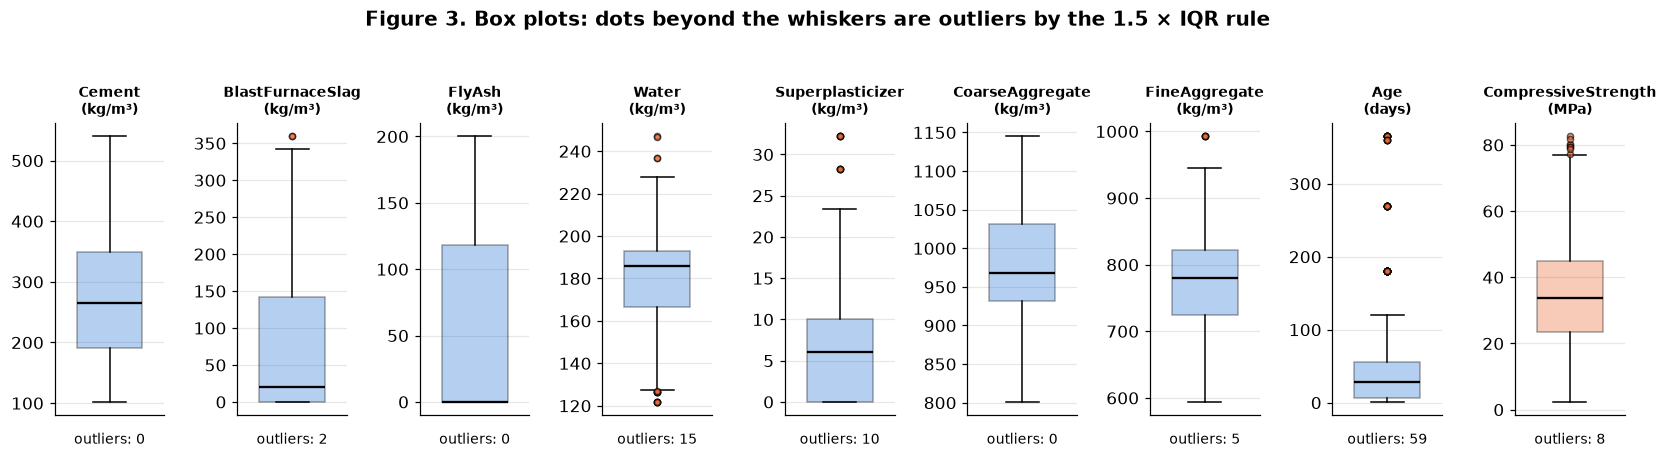

In [7]:
q1, q3 = df.quantile(0.25), df.quantile(0.75)
iqr = q3 - q1
outlier_mask = (df < q1 - 1.5 * iqr) | (df > q3 + 1.5 * iqr)
outliers = pd.DataFrame({"lower fence": (q1 - 1.5 * iqr).round(1), "upper fence": (q3 + 1.5 * iqr).round(1),
                         "outliers (n)": outlier_mask.sum(), "outliers (%)": (100 * outlier_mask.mean()).round(1)})
display(outliers[outliers["outliers (n)"] > 0])

fig, axes = plt.subplots(1, 9, figsize=(15, 4))
for ax, col in zip(axes, FEATURES + [TARGET]):
    ax.boxplot(df[col], widths=0.6, patch_artist=True,
               boxprops=dict(facecolor=ORANGE if col == TARGET else BLUE, alpha=0.35, edgecolor="black"),
               medianprops=dict(color="black", lw=1.5), flierprops=dict(marker="o", markersize=4, markerfacecolor=ORANGE, alpha=0.6))
    ax.set_title(f"{col}\n({UNITS[col]})", fontsize=9)
    ax.set_xticks([])
    ax.text(0.5, -0.06, f"outliers: {outlier_mask[col].sum()}", transform=ax.transAxes, ha="center", va="top", fontsize=9)
fig.suptitle("Figure 3. Box plots: dots beyond the whiskers are outliers by the 1.5 × IQR rule", fontweight="bold", y=1.04)
fig.tight_layout()
save(fig, "fig03_boxplots_outliers")

**Decision: keep every outlier.** The course book separates **true** outliers (real but extreme observations) from **fake** ones (errors). Every flagged value here is physically plausible:
* Age of 180–365 days is a real long-term test.
* Water of 122 or 247 kg/m³ is a very dry or very wet mix.
* Superplasticizer above 25 kg/m³ is a heavily dosed mix.
* Strength above 77 MPa is high-performance concrete.

These are true outliers that carry useful information, and removing them would make the model blind to strong or old concrete.

### 3.3.4 How does each feature relate to strength?

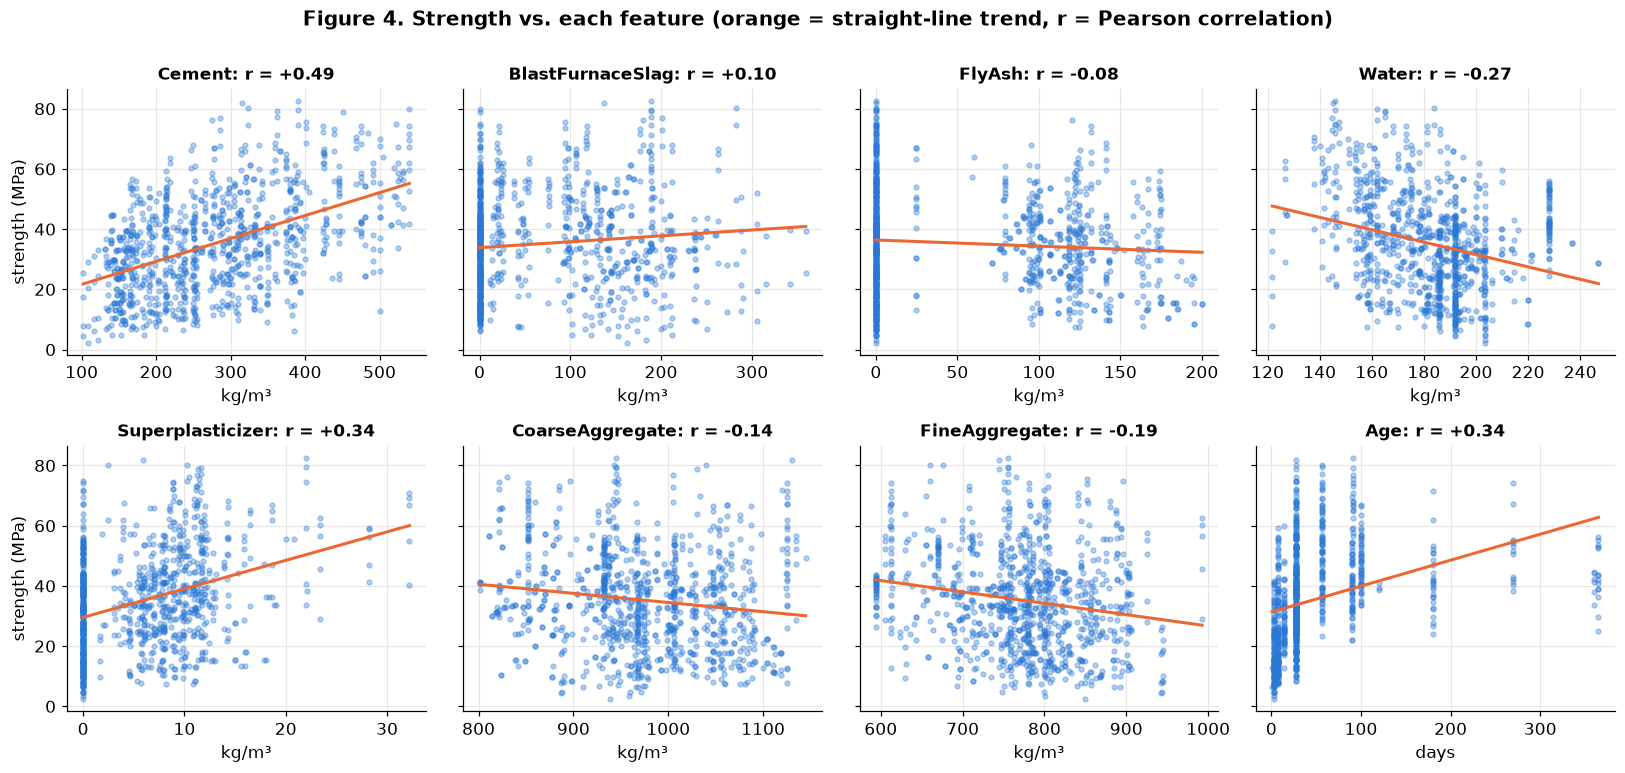

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7), sharey=True)
for ax, col in zip(axes.ravel(), FEATURES):
    r, p = stats.pearsonr(df[col], df[TARGET])
    ax.scatter(df[col], df[TARGET], s=10, alpha=0.35, color=BLUE)
    slope, intercept = np.polyfit(df[col], df[TARGET], 1)
    xs = np.linspace(df[col].min(), df[col].max(), 50)
    ax.plot(xs, intercept + slope * xs, color=ORANGE, lw=2)
    ax.set_title(f"{col}: r = {r:+.2f}", fontsize=11)
    ax.set_xlabel(UNITS[col])
for ax in axes[:, 0]:
    ax.set_ylabel("strength (MPa)")
fig.suptitle("Figure 4. Strength vs. each feature (orange = straight-line trend, r = Pearson correlation)",
             fontweight="bold", y=1.0)
fig.tight_layout()
save(fig, "fig04_feature_vs_strength")

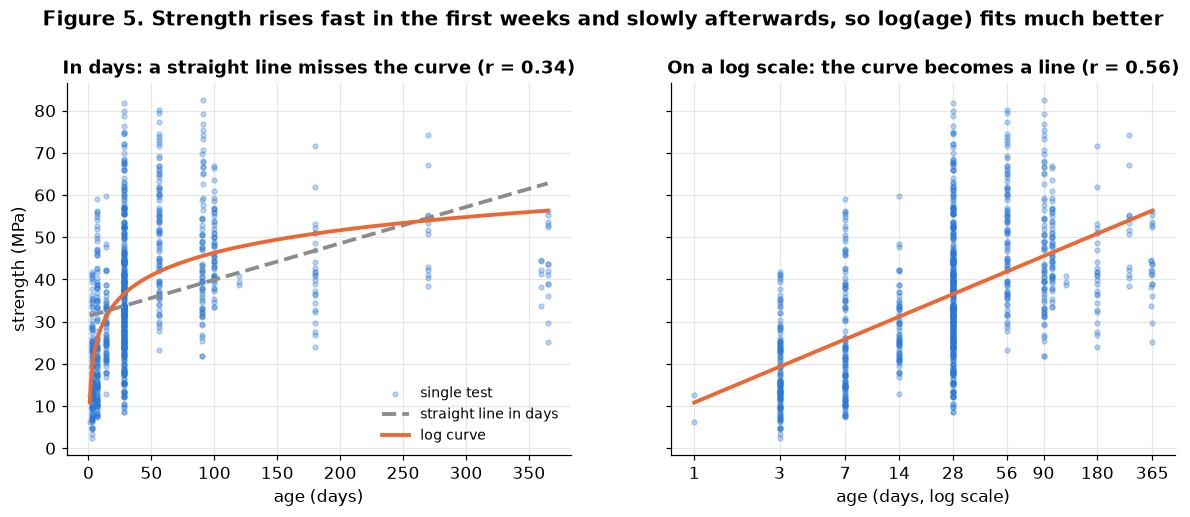

In [9]:
r_age = stats.pearsonr(df["Age"], df[TARGET])[0]
r_logage = stats.pearsonr(np.log(df["Age"]), df[TARGET])[0]
b_lin = np.polyfit(df["Age"], df[TARGET], 1)            # straight line in days
b_log = np.polyfit(np.log(df["Age"]), df[TARGET], 1)    # straight line in log(days)
days = np.linspace(1, 365, 400)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
a1.scatter(df["Age"], df[TARGET], s=10, alpha=0.3, color=BLUE, label="single test")
a1.plot(days, np.polyval(b_lin, days), color=GREY, lw=2.5, ls="--", label="straight line in days")
a1.plot(days, np.polyval(b_log, np.log(days)), color=ORANGE, lw=2.5, label="log curve")
a1.set(xlabel="age (days)", ylabel="strength (MPa)", title=f"In days: a straight line misses the curve (r = {r_age:.2f})")
a1.legend(frameon=False, fontsize=9, loc="lower right")
a2.scatter(np.log(df["Age"]), df[TARGET], s=10, alpha=0.3, color=BLUE)
a2.plot(np.log(days), np.polyval(b_log, np.log(days)), color=ORANGE, lw=2.5)
ticks = [1, 3, 7, 14, 28, 56, 90, 180, 365]
a2.set_xticks(np.log(ticks), [str(t) for t in ticks])
a2.set(xlabel="age (days, log scale)", title=f"On a log scale: the curve becomes a line (r = {r_logage:.2f})")
fig.suptitle("Figure 5. Strength rises fast in the first weeks and slowly afterwards, so log(age) fits much better",
             fontweight="bold", y=1.03)
save(fig, "fig05_age_effect")

**Reading Figures 4 and 5**
* **Cement** has the clearest linear relationship with strength (r ≈ +0.49).
* **Superplasticizer** is positively related (r ≈ +0.34) and **water** negatively (r ≈ −0.27), which matches concrete physics: more water makes weaker concrete.
* **Age** clearly matters, but its effect is **curved**. Strength rises steeply up to about 28 days and then flattens. A straight line through age in days fits badly (r = 0.34). Using **log(age)** straightens the curve (r = 0.56).
* **Hypothesis for the model:** transforming age with a logarithm should improve the linear model. Part 3.6 tests this.

### 3.3.5 Correlation between features and hypothesis tests

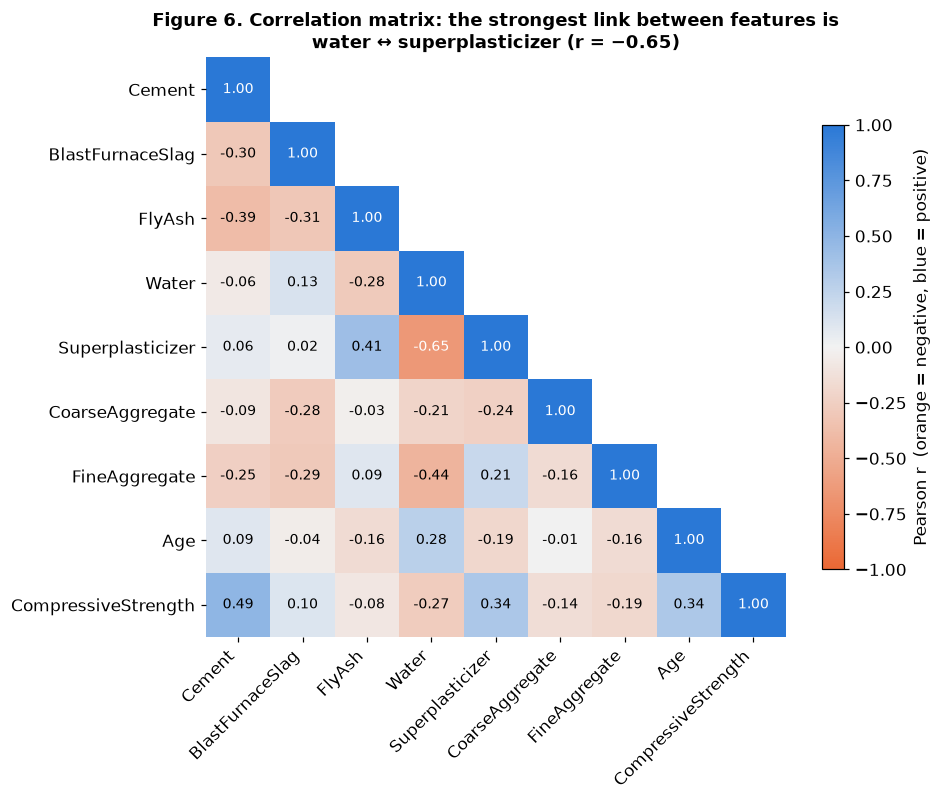

In [10]:
corr = df[FEATURES + [TARGET]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
cmap = matplotlib.colors.LinearSegmentedColormap.from_list("div", [ORANGE, "#f2f2f2", BLUE])
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(np.ma.masked_array(corr.values, mask), cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(i + 1):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
ax.grid(False)
ax.spines[["left", "bottom"]].set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.75, label="Pearson r  (orange = negative, blue = positive)")
ax.set_title("Figure 6. Correlation matrix: the strongest link between features is\nwater ↔ superplasticizer (r = −0.65)")
save(fig, "fig06_correlation_matrix")

In [11]:
# Hypothesis test for each feature.  H0: no linear correlation with strength (rho = 0).  alpha = 5 %.
ALPHA = 0.05
rows = []
for col in FEATURES:
    r, p = stats.pearsonr(df[col], df[TARGET])
    rows.append([col, round(r, 3), p, "reject H0 → significant" if p < ALPHA else "keep H0"])
r_log, p_log = stats.pearsonr(np.log(df["Age"]), df[TARGET])
rows.append(["log(Age)", round(r_log, 3), p_log, "reject H0 → significant" if p_log < ALPHA else "keep H0"])
tests = pd.DataFrame(rows, columns=["feature", "Pearson r", "p-value", f"decision (α = {ALPHA})"])
tests["p-value"] = tests["p-value"].map(lambda v: f"{v:.1e}")
display(tests)

# Multicollinearity: variance inflation factor (VIF > 10 = serious, 5–10 = moderate)
X_vif = sm.add_constant(df[FEATURES])
vif = pd.DataFrame({"feature": FEATURES,
                    "VIF": [round(variance_inflation_factor(X_vif.values, i + 1), 2) for i in range(len(FEATURES))]})
display(vif.sort_values("VIF", ascending=False))

,feature,Pearson r,p-value,decision (α = 0.05)
0,Cement,0.488,2.5e-61,reject H0 → significant
1,BlastFurnaceSlag,0.103,1.0e-03,reject H0 → significant
2,FlyAsh,-0.081,1.1e-02,reject H0 → significant
3,Water,-0.270,3.4e-18,reject H0 → significant
4,Superplasticizer,0.344,2.5e-29,reject H0 → significant
5,CoarseAggregate,-0.145,4.1e-06,reject H0 → significant
6,FineAggregate,-0.186,2.6e-09,reject H0 → significant
7,Age,0.337,3.6e-28,reject H0 → significant
8,log(Age),0.563,4.8e-85,reject H0 → significant


,feature,VIF
0,Cement,7.45
1,BlastFurnaceSlag,7.26
6,FineAggregate,6.97
3,Water,6.84
2,FlyAsh,6.08
5,CoarseAggregate,4.96
4,Superplasticizer,2.87
7,Age,1.12


**Statistical conclusions (summary of 3.3)**
1. **Every feature is significantly correlated with strength** (p < 0.05 in every test), so all 8 features stay in the model. log(age) has a much stronger correlation than raw age.
2. **Correlation is not causation.** These are pairwise associations. The regression in 3.5 measures each ingredient's effect while holding the others constant.
3. **Multicollinearity is moderate, not severe.** VIF values are 5–7.5 for cement, slag, fine aggregate, water and fly ash (none above 10), because the ingredients of 1 m³ of concrete are tied together: more of one leaves less room for another. Weights can still be estimated, but individual weights should be read with care. A Ridge penalty is one remedy and is tested in 3.6.
4. **Preprocessing decisions:**
   * Remove the duplicates (done).
   * Keep the true outliers and true zeros.
   * Try log(age).
   * Standardise the features so that weights are comparable and Ridge treats them equally.

## 3.4 Preprocessing and the train / validation / test split
The course book recommends **70 % training, 10 % validation, 20 % test**.

**One detail matters for an honest test.** Many mixes were crushed at several ages, for example the same recipe at 3, 7, 28 and 90 days. If the 28-day result of a mix landed in training and its 90-day result in the test set, the model would be tested on a recipe it already knows. That would overstate its accuracy on genuinely new mixes. Every recipe therefore gets a **mix ID**, and all rows of one mix go into the same set (a group split).

In [12]:
df["mix_id"] = df.groupby(INGREDIENTS, sort=False).ngroup()
print(f"{df['mix_id'].nunique()} different mixes; {(df['mix_id'].value_counts() > 1).sum()} of them were tested at more than one age")

X, y, groups = df[FEATURES], df[TARGET], df["mix_id"]

# Step 1: 20 % of the mixes → test set.  Step 2: 12.5 % of the remaining 80 % (= 10 % overall) → validation set.
idx_rest, idx_test = next(GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE).split(X, y, groups))
rest_tr, rest_val = next(GroupShuffleSplit(n_splits=1, test_size=0.125, random_state=RANDOM_STATE)
                         .split(X.iloc[idx_rest], y.iloc[idx_rest], groups.iloc[idx_rest]))
idx_train, idx_val = idx_rest[rest_tr], idx_rest[rest_val]

X_train, y_train, g_train = X.iloc[idx_train], y.iloc[idx_train], groups.iloc[idx_train]
X_val, y_val = X.iloc[idx_val], y.iloc[idx_val]
X_test, y_test = X.iloc[idx_test], y.iloc[idx_test]

assert not set(groups.iloc[idx_train]) & set(groups.iloc[idx_val])
assert not set(groups.iloc[idx_train]) & set(groups.iloc[idx_test])
assert not set(groups.iloc[idx_val]) & set(groups.iloc[idx_test])

split_summary = pd.DataFrame({
    "rows": [len(idx_train), len(idx_val), len(idx_test)],
    "share of rows": [f"{len(i) / len(df):.0%}" for i in (idx_train, idx_val, idx_test)],
    "mixes": [groups.iloc[i].nunique() for i in (idx_train, idx_val, idx_test)],
    "mean strength (MPa)": [round(s.mean(), 1) for s in (y_train, y_val, y_test)],
    "std strength (MPa)": [round(s.std(), 1) for s in (y_train, y_val, y_test)],
}, index=["training", "validation", "test"])
display(split_summary)
ks = stats.ks_2samp(y_train, y_test)
print(f"Kolmogorov–Smirnov test, strength train vs test: p = {ks.pvalue:.2f} "
      f"({'no significant difference' if ks.pvalue > 0.05 else 'different distributions'})")

427 different mixes; 181 of them were tested at more than one age


,rows,share of rows,mixes,mean strength (MPa),std strength (MPa)
training,672,67%,298,35.5,16.3
validation,128,13%,43,33.7,13.4
test,205,20%,86,35.5,17.8


Kolmogorov–Smirnov test, strength train vs test: p = 0.74 (no significant difference)


* **No mix appears in more than one set.** The asserts check this.
* **The split is close to the 70 / 10 / 20 target.** Splitting by whole mixes makes the shares approximate.
* **The training and test strength distributions do not differ significantly** (Kolmogorov–Smirnov test above), so the test set is representative.

**Preprocessing** is built into each model as a scikit-learn `Pipeline`:
* the optional log(age) transform
* `StandardScaler`, which subtracts the mean and divides by the SD
* the optional polynomial terms
* the regression

The pipeline is fitted on training data only, so the validation and test sets never influence the scaling or the weights (no data leakage).

## 3.5 First model: plain linear regression (scikit-learn)
Two reference points are trained on the training set and scored on the validation set:
* the **naive benchmark**, which always predicts the training mean
* **plain linear regression** on the 8 raw features

In [13]:
def scores(y_true, y_pred):
    # Course-book regression metrics
    return {"MAE (MPa)": mean_absolute_error(y_true, y_pred),
            "RMSE (MPa)": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R²": r2_score(y_true, y_pred),
            "MAPE (%)": 100 * np.mean(np.abs((y_true - y_pred) / y_true))}

log_age = ColumnTransformer([("log_age", FunctionTransformer(np.log, feature_names_out="one-to-one"), ["Age"])],
                            remainder="passthrough", verbose_feature_names_out=False)

plain_lr = Pipeline([("scale", StandardScaler()), ("model", LinearRegression())]).fit(X_train, y_train)
results_val = pd.DataFrame({
    "Naive benchmark (always the mean)": scores(y_val, np.full(len(y_val), y_train.mean())),
    "Plain linear regression": scores(y_val, plain_lr.predict(X_val)),
}).T
display(results_val.round(2))
print("Training R² of plain linear regression:", round(r2_score(y_train, plain_lr.predict(X_train)), 3))

,MAE (MPa),RMSE (MPa),R²,MAPE (%)
Naive benchmark (always the mean),10.79,13.44,-0.02,49.91
Plain linear regression,8.12,10.74,0.35,31.65


Training R² of plain linear regression: 0.614


* **Plain linear regression already beats the naive benchmark clearly.** The average error (MAE) falls from about 10.8 to about 8.1 MPa.
* **It is still weak.** R² is only about 0.6 on the training data and about 0.35 on the validation set.
* **The main cause is the curved age effect seen in Figure 5.** A straight line in days cannot follow it. The next step tests that hypothesis.

## 3.6 Hyperparameter tuning
**Hyperparameters searched** (grid search):
* **Age transform:** raw days vs log(age), the hypothesis from 3.3.
* **Polynomial degree:** 1 (straight), 2 (squares and pairwise interactions) or 3.
* **Ridge penalty α:** 0.0001 to 1,000, on a log scale.

**Procedure.**
* `GridSearchCV` with **5-fold cross-validation on the training set only**, grouped by mix (`GroupKFold`), so every fold is also tested on unseen mixes.
* Each of the 48 combinations is trained 5 times. The winner is the one with the lowest average **RMSE**.
* Cross-validation decides because it averages 5 tests over about 300 mixes. The validation set (about 40 mixes) then confirms that the chosen model improves on the models from 3.5.

In [14]:
pipeline = Pipeline([
    ("age", "passthrough"),
    ("scale", StandardScaler()),
    ("poly", PolynomialFeatures(degree=1, include_bias=False)),
    ("scale_poly", StandardScaler()),
    ("model", Ridge()),
])
param_grid = {
    "age": ["passthrough", log_age],
    "poly__degree": [1, 2, 3],
    "model__alpha": [1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100, 1000],
}
search = GridSearchCV(pipeline, param_grid, cv=GroupKFold(n_splits=5),
                      scoring="neg_root_mean_squared_error", return_train_score=True)
search.fit(X_train, y_train, groups=g_train)

cv = pd.DataFrame(search.cv_results_)
cv["age transform"] = cv["param_age"].map(lambda v: "raw days" if isinstance(v, str) else "log(age)")
cv["degree"] = cv["param_poly__degree"].astype(int)
cv["alpha"] = cv["param_model__alpha"].astype(float)
cv["CV RMSE"] = -cv["mean_test_score"]
cv["CV RMSE std"] = cv["std_test_score"]
cv["train RMSE"] = -cv["mean_train_score"]
best = cv.loc[cv["CV RMSE"].idxmin()]
print("Best combination:", {"age": best["age transform"], "degree": best["degree"], "alpha": best["alpha"]},
      f"→ CV RMSE = {best['CV RMSE']:.2f} ± {best['CV RMSE std']:.2f} MPa")

best_per_setting = (cv.sort_values("CV RMSE").groupby(["age transform", "degree"]).head(1)
                    [["age transform", "degree", "alpha", "train RMSE", "CV RMSE", "CV RMSE std"]]
                    .sort_values(["age transform", "degree"]).round(2))
best_per_setting.to_csv(OUT_DIR / "tuning_best_per_setting.csv", index=False)
display(best_per_setting)

Best combination: {'age': 'log(age)', 'degree': np.int64(2), 'alpha': np.float64(0.0001)} → CV RMSE = 6.52 ± 0.71 MPa


,age transform,degree,alpha,train RMSE,CV RMSE,CV RMSE std
24,log(age),1,0.0,6.95,7.14,0.61
25,log(age),2,0.0,5.30,6.52,0.71
44,log(age),3,100.0,5.35,7.39,1.38
0,raw days,1,0.0,10.10,10.25,0.28
1,raw days,2,0.0,6.89,7.93,0.48
14,raw days,3,1.0,4.59,8.58,1.70


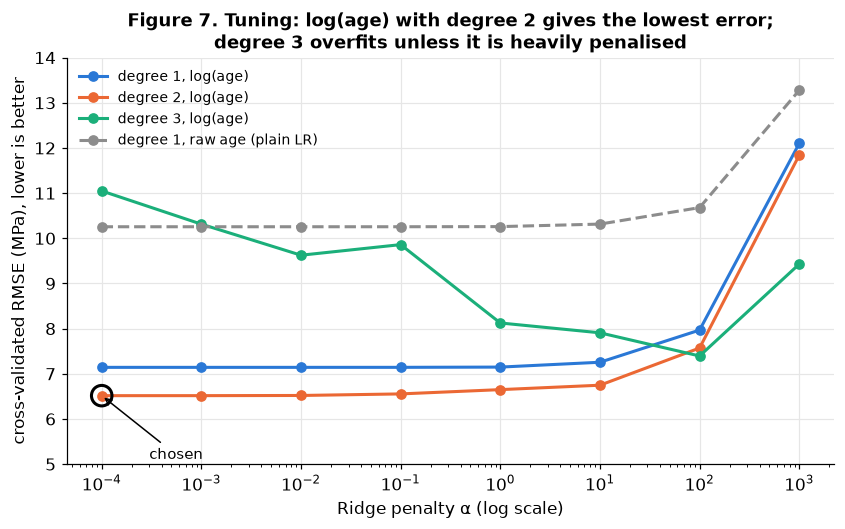

In [15]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for deg, color in zip([1, 2, 3], [BLUE, ORANGE, GREEN]):
    sub = cv[(cv["age transform"] == "log(age)") & (cv["degree"] == deg)].sort_values("alpha")
    ax.plot(sub["alpha"], sub["CV RMSE"], marker="o", color=color, lw=2, label=f"degree {deg}, log(age)")
raw = cv[(cv["age transform"] == "raw days") & (cv["degree"] == 1)].sort_values("alpha")
ax.plot(raw["alpha"], raw["CV RMSE"], marker="o", color=GREY, lw=2, ls="--", label="degree 1, raw age (plain LR)")
ax.scatter([best["alpha"]], [best["CV RMSE"]], s=180, facecolor="none", edgecolor="black", lw=2, zorder=4)
ax.annotate("chosen", (best["alpha"], best["CV RMSE"]), xytext=(best["alpha"] * 3, best["CV RMSE"] - 1.4),
            arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.set_xscale("log")
ax.set_ylim(5, 14)
ax.set(xlabel="Ridge penalty α (log scale)", ylabel="cross-validated RMSE (MPa), lower is better")
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.set_title("Figure 7. Tuning: log(age) with degree 2 gives the lowest error;\ndegree 3 overfits unless it is heavily penalised")
save(fig, "fig07_hyperparameter_tuning")

**Reading Figure 7 and the table**
* **log(age) is the biggest single improvement.** The grey dashed line (raw age, degree 1, about 10.3 MPa) drops to the blue line (log(age), degree 1, about 7.1 MPa). The hypothesis from 3.3 is confirmed by cross-validation.
* **Degree 2 helps further** (orange, about 6.5 MPa). Squares and interactions let the model capture effects like "cement matters more as the concrete ages".
* **Degree 3 overfits.** With 164 terms it fits the training folds well but fails on unseen mixes (green line, high error). A strong Ridge penalty (α ≈ 100) is needed just to bring it down to about 7.4 MPa, still worse than degree 2.
* **For degree 2 the penalty hardly matters.** The orange line is flat for small α, so the chosen model is practically ordinary least squares.

The table shows the training-vs-CV gap: degree 3 has a low training error but a high CV error, the classic sign of overfitting.

,MAE (MPa),RMSE (MPa),R²,MAPE (%)
Naive benchmark (always the mean),10.79,13.44,-0.02,49.91
Plain linear regression,8.12,10.74,0.35,31.65
Linear regression + log(age),5.91,7.52,0.68,18.89
Tuned: log(age) + degree 2 + Ridge,4.76,6.38,0.77,15.60


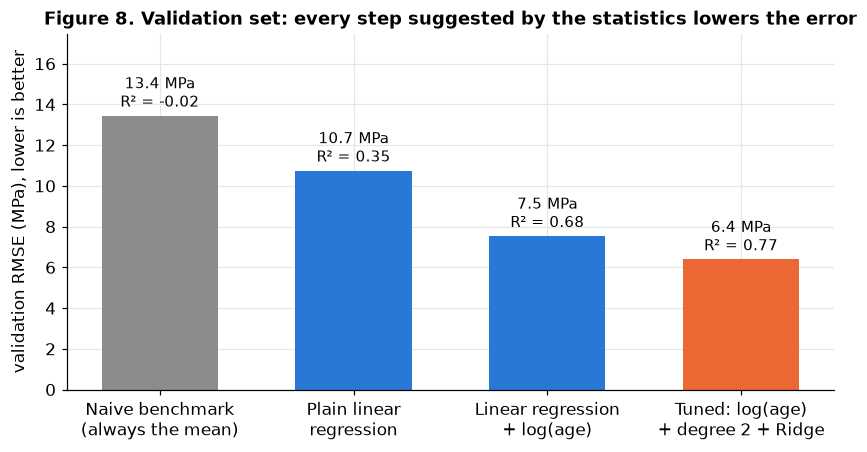

In [16]:
log_lr = Pipeline([("age", log_age), ("scale", StandardScaler()), ("model", LinearRegression())]).fit(X_train, y_train)
tuned = search.best_estimator_
results_val.loc["Linear regression + log(age)"] = scores(y_val, log_lr.predict(X_val))
results_val.loc["Tuned: log(age) + degree 2 + Ridge"] = scores(y_val, tuned.predict(X_val))
results_val.round(2).to_csv(OUT_DIR / "validation_results.csv")
display(results_val.round(2))

fig, ax = plt.subplots(figsize=(9, 4.2))
names = ["Naive benchmark\n(always the mean)", "Plain linear\nregression", "Linear regression\n+ log(age)", "Tuned: log(age)\n+ degree 2 + Ridge"]
vals = results_val["RMSE (MPa)"].values
bars = ax.bar(names, vals, color=[GREY, BLUE, BLUE, ORANGE], width=0.6)
for b, v, r2 in zip(bars, vals, results_val["R²"].values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.2, f"{v:.1f} MPa\nR² = {r2:.2f}", ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, vals.max() * 1.3)
ax.set_ylabel("validation RMSE (MPa), lower is better")
ax.set_title("Figure 8. Validation set: every step suggested by the statistics lowers the error")
save(fig, "fig08_validation_comparison")

**The validation set confirms the progression** (Figure 8). The validation RMSE falls from about 13.4 MPa (naive), to about 10.7 (plain LR), to about 7.5 (log(age)), to about 6.4 MPa (tuned), and R² rises from 0 to about 0.77.

**Final model:** log(age) → standardise → degree-2 polynomial terms → Ridge (α = 0.0001). Before the test, it is refitted on training + validation data (80 %) with these hyperparameters, so it learns from as much data as possible. The test set is then used **once**.

## 3.7 Final evaluation on the untouched test set

In [17]:
X_dev, y_dev = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
final_model = clone(search.best_estimator_).fit(X_dev, y_dev)
plain_dev = Pipeline([("scale", StandardScaler()), ("model", LinearRegression())]).fit(X_dev, y_dev)
logage_dev = Pipeline([("age", log_age), ("scale", StandardScaler()), ("model", LinearRegression())]).fit(X_dev, y_dev)

pred_test = final_model.predict(X_test)
test_results = pd.DataFrame({
    "Naive benchmark (always the mean)": scores(y_test, np.full(len(y_test), y_dev.mean())),
    "Plain linear regression": scores(y_test, plain_dev.predict(X_test)),
    "Linear regression + log(age)": scores(y_test, logage_dev.predict(X_test)),
    "Final tuned model": scores(y_test, pred_test),
}).T

# 95 % bootstrap confidence intervals for the final model (2,000 resamples of the test set)
rng = np.random.default_rng(RANDOM_STATE)
boot = []
yt = y_test.to_numpy()
for _ in range(2000):
    i = rng.integers(0, len(yt), len(yt))
    boot.append([mean_absolute_error(yt[i], pred_test[i]), np.sqrt(mean_squared_error(yt[i], pred_test[i])), r2_score(yt[i], pred_test[i])])
ci = np.percentile(boot, [2.5, 97.5], axis=0)
test_results["95 % CI (final model)"] = ""
test_results.loc["Final tuned model", "95 % CI (final model)"] = (
    f"MAE {ci[0,0]:.1f}–{ci[1,0]:.1f} | RMSE {ci[0,1]:.1f}–{ci[1,1]:.1f} | R² {ci[0,2]:.2f}–{ci[1,2]:.2f}")
test_results.round(2).to_csv(OUT_DIR / "test_results.csv")
display(test_results.round(2))
within5 = np.mean(np.abs(pred_test - yt) <= 5)
print(f"Share of test predictions within ±5 MPa of the measured strength: {within5:.0%}")

# Is the tuned model really better than the simpler log(age) model on the test set?  Paired bootstrap of the RMSE difference
pred_simple = logage_dev.predict(X_test)
diff = []
for _ in range(2000):
    i = rng.integers(0, len(yt), len(yt))
    diff.append(np.sqrt(mean_squared_error(yt[i], pred_simple[i])) - np.sqrt(mean_squared_error(yt[i], pred_test[i])))
lo, hi = np.percentile(diff, [2.5, 97.5])
print(f"RMSE(simple log-age model) − RMSE(tuned model) on the test set: {np.mean(diff):+.2f} MPa, 95 % CI {lo:+.2f} to {hi:+.2f}")

,MAE (MPa),RMSE (MPa),R²,MAPE (%),95 % CI (final model)
Naive benchmark (always the mean),14.40,17.81,-0.00,65.98,
Plain linear regression,8.48,10.72,0.64,35.27,
Linear regression + log(age),5.40,7.40,0.83,19.02,
Final tuned model,5.22,7.42,0.83,17.91,MAE 4.5–6.0 | RMSE 6.3–8.6 | R² 0.76–0.88


Share of test predictions within ±5 MPa of the measured strength: 61%
RMSE(simple log-age model) − RMSE(tuned model) on the test set: -0.03 MPa, 95 % CI -1.29 to +1.14


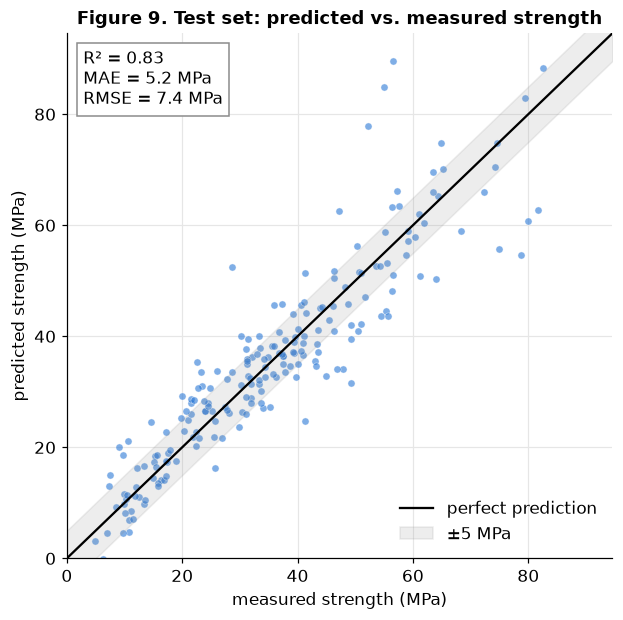

In [18]:
fig, ax = plt.subplots(figsize=(6.4, 6.2))
ax.scatter(y_test, pred_test, s=22, alpha=0.6, color=BLUE, edgecolor="white", linewidth=0.4)
lim = [0, max(y_test.max(), pred_test.max()) + 5]
ax.plot(lim, lim, color="black", lw=1.5, label="perfect prediction")
ax.fill_between(lim, [l - 5 for l in lim], [l + 5 for l in lim], color=GREY, alpha=0.15, label="±5 MPa")
ax.set(xlim=lim, ylim=lim, xlabel="measured strength (MPa)", ylabel="predicted strength (MPa)")
m = scores(y_test, pred_test)
ax.text(0.03, 0.97, f"R² = {m['R²']:.2f}\nMAE = {m['MAE (MPa)']:.1f} MPa\nRMSE = {m['RMSE (MPa)']:.1f} MPa",
        transform=ax.transAxes, va="top", fontsize=11, bbox=dict(facecolor="white", edgecolor=GREY))
ax.legend(frameon=False, loc="lower right")
ax.set_title("Figure 9. Test set: predicted vs. measured strength")
save(fig, "fig09_predicted_vs_actual")

**Reading Figure 9 and the table**
* **The points follow the diagonal.** The final model explains about **83 % of the variance** in the strength of concrete mixes it has never seen (R² ≈ 0.83). The typical error is about **5.2 MPa** (MAE).
* **It beats both references.** The naive benchmark misses by about 14 MPa on average and plain linear regression by about 8.5 MPa.
* **The bootstrap confidence interval shows the uncertainty** of these test numbers. With 205 test rows, the true R² is plausibly between about 0.76 and 0.88.
* **Most predictions are close.** About 6 in 10 land within ±5 MPa of the measured strength (shaded band).
* **Honest finding: the simpler model is just as good on the test set.** The plain linear regression with only log(age) reaches the same test RMSE (≈ 7.4 MPa). The paired bootstrap interval for the difference includes 0. Degree 2 looked better in cross-validation and on the validation set, but that gain did not carry over to these test mixes. **Most of the improvement comes from the log(age) step that the statistical analysis suggested.** The extra 36 polynomial terms add little. In practice the simpler, fully interpretable model is the better choice. The tuned model stays the "final" model only because it was chosen before the test set was opened, and switching after looking at the test would be cheating.

### Checking the regression assumptions (residual analysis)

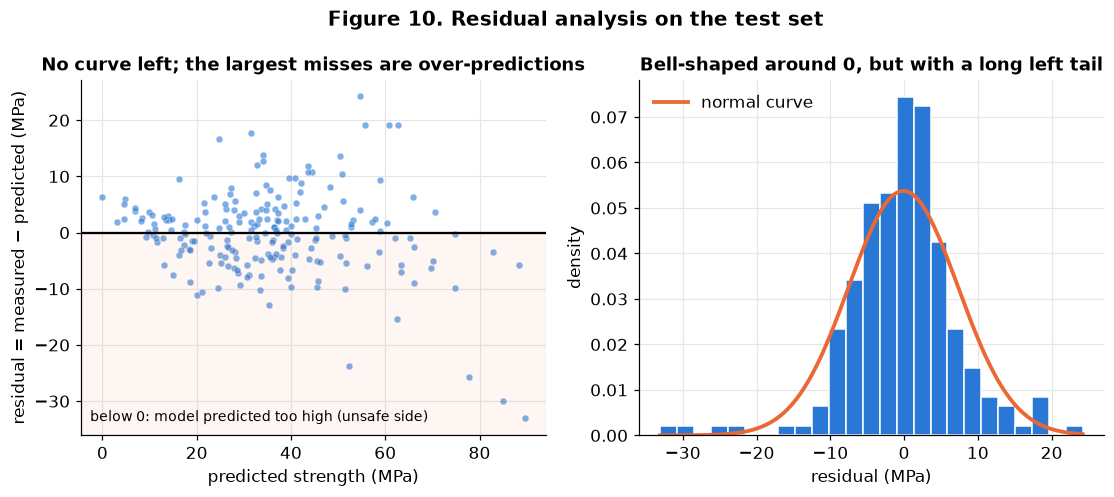

,assumption,observation,test (H0 = assumption holds),p-value
0,Errors centred on zero (no bias),mean residual = -0.10 MPa,one-sample t-test,0.85
1,Normal errors,skewness = -0.53,Shapiro–Wilk,0.000
2,Constant error spread,residual spread vs. features,Breusch–Pagan,0.000


In [19]:
resid = yt - pred_test
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
a1.scatter(pred_test, resid, s=20, alpha=0.6, color=BLUE, edgecolor="white", linewidth=0.4)
a1.axhline(0, color="black", lw=1.5)
a1.axhspan(resid.min() - 3, 0, color=ORANGE, alpha=0.06)
a1.text(0.02, 0.04, "below 0: model predicted too high (unsafe side)", transform=a1.transAxes, fontsize=9, color="black")
a1.set_ylim(resid.min() - 3, resid.max() + 3)
a1.set(xlabel="predicted strength (MPa)", ylabel="residual = measured − predicted (MPa)",
       title="No curve left; the largest misses are over-predictions")
a2.hist(resid, bins=25, density=True, color=BLUE, edgecolor="white")
xs = np.linspace(resid.min(), resid.max(), 200)
a2.plot(xs, stats.norm.pdf(xs, resid.mean(), resid.std()), color=ORANGE, lw=2.5, label="normal curve")
a2.set(xlabel="residual (MPa)", ylabel="density", title="Bell-shaped around 0, but with a long left tail")
a2.legend(frameon=False)
fig.suptitle("Figure 10. Residual analysis on the test set", fontweight="bold", y=1.03)
save(fig, "fig10_residuals")

shapiro_p = stats.shapiro(resid).pvalue
bp_p = het_breuschpagan(resid, sm.add_constant(X_test.to_numpy()))[1]
assumptions = pd.DataFrame([
    ["Errors centred on zero (no bias)", f"mean residual = {resid.mean():+.2f} MPa", "one-sample t-test", f"{stats.ttest_1samp(resid, 0).pvalue:.2f}"],
    ["Normal errors", f"skewness = {stats.skew(resid):.2f}", "Shapiro–Wilk", f"{shapiro_p:.3f}"],
    ["Constant error spread", "residual spread vs. features", "Breusch–Pagan", f"{bp_p:.3f}"],
], columns=["assumption", "observation", "test (H0 = assumption holds)", "p-value"])
display(assumptions)

**Reading Figure 10 and the tests**
* **Linearity holds.** The residuals scatter around 0 with no curve left. log(age) and the degree-2 terms removed the curvature that plain linear regression could not handle.
* **No systematic bias.** The mean residual is about −0.1 MPa and the t-test is not significant (p ≈ 0.85), so on average the model neither over- nor under-predicts.
* **Normality is rejected** (Shapiro–Wilk p < 0.001). The middle of the distribution is bell-shaped, but there is a **long left tail**: a few very strong predicted mixes were much weaker in reality. For example, one mix was predicted at about 90 MPa and measured at about 57 MPa. These are the **unsafe** errors (shaded area) and the main reason the model must not replace the physical test.
* **Constant spread is rejected** (Breusch–Pagan p < 0.001). Errors grow for stronger concrete, which is common in strength data. The predictions remain unbiased. Only the uncertainty of the weights is affected, so Section 3.8 uses robust (HC3) standard errors.
* **Independence holds by design**, because the split keeps all rows of a mix together.

## 3.8 What drives strength? Interpreting the weights
The degree-2 model has 44 terms, too many to read one by one. To explain the effect of each ingredient, the simpler **linear regression with log(age)** (8 weights) is fitted on the same training + validation data.
* **Standardised weight:** change in strength (MPa) when the feature rises by one standard deviation, the others held constant.
* **t-test p-value:** H0 says the weight is 0. Robust (HC3) standard errors are used because the error spread is not constant.

,weight per unit,unit,95 % CI,p-value,standardised weight (MPa per SD)
bias w₀,-80.540,MPa (bias w₀),-129.862 to -31.218,1.4e-03,–
Cement,0.133,MPa per kg/m³,0.118 to 0.149,1.4e-64,13.59
BlastFurnaceSlag,0.110,MPa per kg/m³,0.091 to 0.129,2.2e-30,9.54
FlyAsh,0.092,MPa per kg/m³,0.071 to 0.113,4.8e-18,5.88
Water,-0.113,MPa per kg/m³,-0.190 to -0.037,3.8e-03,-2.43
Superplasticizer,0.221,MPa per kg/m³,0.048 to 0.394,1.2e-02,1.26
CoarseAggregate,0.029,MPa per kg/m³,0.012 to 0.046,6.4e-04,2.2
FineAggregate,0.038,MPa per kg/m³,0.019 to 0.058,1.3e-04,3.19
log(Age),8.455,MPa per 1 log-day,8.020 to 8.889,< 1e-300,10.16


Explanatory model, test R² = 0.83  |  OLS adjusted R² (train+val) = 0.80


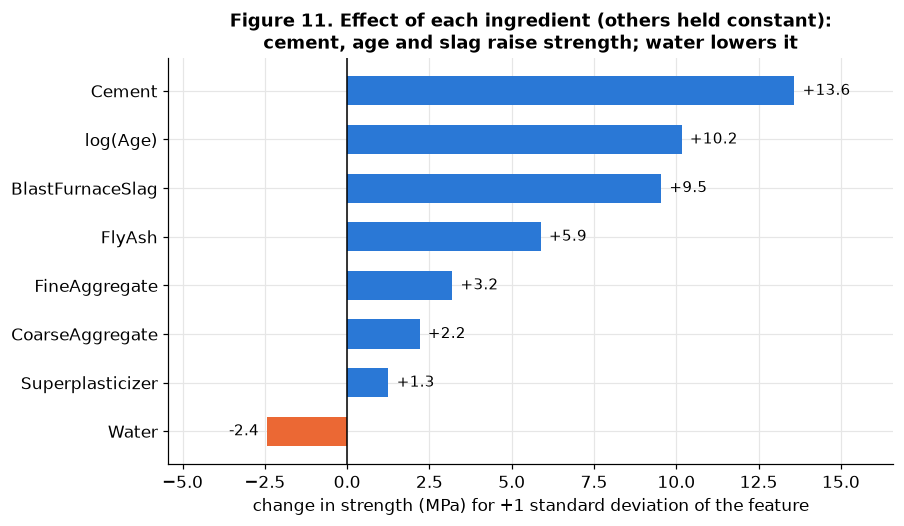

In [20]:
explain = Pipeline([("age", log_age), ("scale", StandardScaler()), ("model", LinearRegression())]).fit(X_dev, y_dev)
names_out = list(explain[:-1].get_feature_names_out())
std_w = pd.Series(explain.named_steps["model"].coef_, index=[n.replace("Age", "log(Age)") for n in names_out])

# Same model with statsmodels for confidence intervals and p-values (weights in original units)
X_ols = X_dev.copy()
X_ols["Age"] = np.log(X_ols["Age"])
ols = sm.OLS(y_dev, sm.add_constant(X_ols)).fit(cov_type="HC3")   # robust SEs: error spread is not constant (3.7)
coef_table = pd.DataFrame({
    "weight per unit": ols.params.round(3),
    "unit": ["MPa (bias w₀)"] + [f"MPa per {'1 log-day' if c == 'Age' else 'kg/m³'}" for c in X_ols.columns],
    "95 % CI": [f"{lo:.3f} to {hi:.3f}" for lo, hi in ols.conf_int().to_numpy()],
    "p-value": ols.pvalues.map(lambda v: f"{v:.1e}" if v > 0 else "< 1e-300"),
})
coef_table.index = ["bias w₀"] + [c.replace("Age", "log(Age)") for c in X_ols.columns]
coef_table["standardised weight (MPa per SD)"] = ["–"] + [round(std_w[c], 2) for c in coef_table.index[1:]]
coef_table.to_csv(OUT_DIR / "coefficients_explanatory_model.csv")
display(coef_table)
print(f"Explanatory model, test R² = {r2_score(y_test, explain.predict(X_test)):.2f}  |  OLS adjusted R² (train+val) = {ols.rsquared_adj:.2f}")

w = std_w.sort_values()
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.barh(w.index, w.values, color=[BLUE if v > 0 else ORANGE for v in w.values], height=0.6)
for i, v in enumerate(w.values):
    ax.text(v + (0.25 if v > 0 else -0.25), i, f"{v:+.1f}", va="center", ha="left" if v > 0 else "right", fontsize=10)
ax.axvline(0, color="black", lw=1)
ax.set_xlim(w.min() - 3, w.max() + 3)
ax.set_xlabel("change in strength (MPa) for +1 standard deviation of the feature")
ax.set_title("Figure 11. Effect of each ingredient (others held constant):\ncement, age and slag raise strength; water lowers it")
save(fig, "fig11_feature_effects")

**Reading Figure 11 and the table**
* **Cement** has the largest positive effect: it is the binder.
* **Age (log)** comes next: concrete keeps hardening, fastest in the first weeks.
* **Slag and fly ash also raise strength** when they are added to a mix with the other ingredients held fixed. This supports replacing part of the cement with them to cut CO₂.
* **Water** is the only clearly negative ingredient. This matches the well-known water–cement-ratio rule: extra water leaves pores and weakens concrete.
* **Superplasticizer and the aggregates** have small effects once the other ingredients are known.
* **Per kg, cement (≈ 0.13 MPa) beats slag (≈ 0.11) and fly ash (≈ 0.09).** Replacing 1 kg of cement with slag costs only a little strength, which is useful for low-CO₂ mixes.
* **This simple model reaches test R² ≈ 0.83**, the same as the tuned model (Section 3.7).

Because of the moderate multicollinearity (VIF up to 7.5, Section 3.3.5), read the small weights with care. The signs of the large weights agree with concrete physics, which supports trusting the model.

## 3.9 Bias and limitations
The course book (Section 3.4.2, algorithmic bias) names three ways data introduce bias: data creation, data source and model development. It also names the data scientist's own biases. Each is checked below.

,n,MAE,mean_error
group,,,
1–7 days,58,4.32,0.06
14–28 days,95,5.60,0.07
56–90 days,29,5.39,-0.52
91–365 days,23,5.70,-0.64


Kruskal–Wallis test, H0 = equal absolute error in every age group: p = 0.236


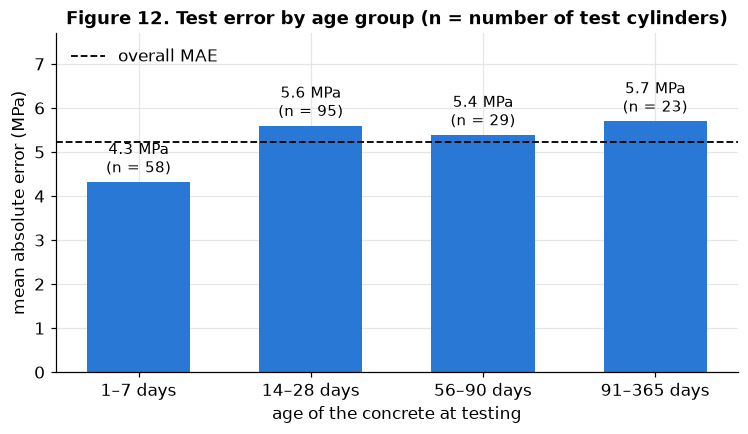

In [21]:
bins = [0, 7, 28, 90, 365]
age_group = pd.cut(X_test["Age"], bins=bins, labels=["1–7 days", "14–28 days", "56–90 days", "91–365 days"])
by_age = (pd.DataFrame({"group": age_group, "abs_error": np.abs(resid), "error": resid})
          .groupby("group", observed=True).agg(n=("abs_error", "size"), MAE=("abs_error", "mean"), mean_error=("error", "mean")).round(2))
display(by_age)
kw = stats.kruskal(*[np.abs(resid)[age_group == g] for g in by_age.index])
print(f"Kruskal–Wallis test, H0 = equal absolute error in every age group: p = {kw.pvalue:.3f}")

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(by_age.index.astype(str), by_age["MAE"], color=BLUE, width=0.6)
for b, n, v in zip(bars, by_age["n"], by_age["MAE"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.1, f"{v:.1f} MPa\n(n = {n})", ha="center", va="bottom", fontsize=10)
ax.axhline(np.abs(resid).mean(), color="black", ls="--", lw=1.2, label="overall MAE")
ax.set_ylim(0, by_age["MAE"].max() * 1.35)
ax.set(xlabel="age of the concrete at testing", ylabel="mean absolute error (MPa)")
ax.legend(frameon=False, loc="upper left")
ax.set_title("Figure 12. Test error by age group (n = number of test cylinders)")
save(fig, "fig12_error_by_age_group")

**Reading Figure 12.**
* **The error is similar in every age group** (MAE 4.3–5.7 MPa). The Kruskal–Wallis test finds no significant difference (p ≈ 0.24), so there is no evidence that the model is unfair to young or old concrete.
* **The oldest group has only 23 test cylinders**, so its estimate is uncertain, and the model slightly over-predicts it on average (mean error ≈ −0.6 MPa). This is the data-source bias from the table below: few long-term tests in the data mean less certainty there.

| Source of bias (course book) | In this project | What was done |
|---|---|---|
| **Data creation** | Strength comes from a physical crushing test, not a human opinion, so the risk is low. Different labs and cylinder handling still add measurement noise. | Duplicates removed; repeated tests of the same mix kept together in one split |
| **Data source** | The 1,030 tests were compiled from **17 different sources** (Yeh, 1998) and are not a random sample of all concrete. Ages are unevenly covered: most tests are at 28 days, few at 1–3 or 180–365 days. | Figure 12 checks the error per age group. The model should only be used inside the observed ranges of each ingredient. |
| **Model development** | Important variables are missing: cement type, curing temperature and humidity, aggregate size and water quality. Their effect ends up in the error term. | Reported as a limitation. The test is done on unseen mixes, so the stated accuracy is realistic. |
| **Confirmation bias** | Believing the log(age) idea without testing it | The idea was only accepted after grouped cross-validation confirmed it (Figure 7) |
| **Overconfidence** | Quoting a single test score as exact | 95 % confidence intervals are reported, plus the residual and per-age-group checks |
| **Ego depletion (defaults)** | Keeping default settings | 48 hyperparameter combinations were searched instead of keeping the defaults |

## 3.10 Conclusion
* **Paradigm:** linear regression is a **supervised** learning method for a **regression** task (labelled data, continuous target).
* **Method:** least squares chooses the weights that minimise the squared prediction error. Feature transformation, polynomial degree and the Ridge penalty are its hyperparameters.
* **Statistics first:**
  * Clean data, with 25 duplicates removed and true outliers and zeros kept.
  * All features significantly correlated with strength.
  * Moderate multicollinearity.
  * A curved age effect, which was the key finding.
* **Results on unseen concrete mixes (test set):**

| Model | MAE (MPa) | RMSE (MPa) | R² |
|---|---|---|---|
| Naive benchmark (always the mean) | 14.4 | 17.8 | 0.00 |
| Plain linear regression | 8.5 | 10.7 | 0.64 |
| Linear regression + log(age) | 5.4 | 7.4 | 0.83 |
| Tuned (log(age), degree 2, Ridge) | 5.2 | 7.4 | 0.83 |

* **Main lesson:** the statistical analysis found the curved age effect, and one log transform raised R² from 0.64 to 0.83. Tuning added complexity that did not pay off on unseen mixes, so the simple 8-weight model is recommended.

* **Why linear regression suits this problem:**
  * It is accurate enough for an early screening estimate, about 6 in 10 predictions within ±5 MPa.
  * Its weights match concrete physics (cement and age up, water down).
  * It quantifies how slag and fly ash affect strength, which matters for low-CO₂ mixes.
* **Limits:**
  * It does not replace the 28-day acceptance test. The largest errors are over-predictions of strong mixes, which is the unsafe direction.
  * It is less certain for old concrete, where there are few long-term tests, and outside the ingredient ranges seen in the data.
  * Missing variables, such as cement type and curing conditions, limit the accuracy.

In [22]:
joblib.dump(final_model, OUT_DIR / "final_model.joblib")
print("Saved: outputs/final_model.joblib")

# Example: predict a new mix (a typical 28-day mix with some fly ash)
new_mix = pd.DataFrame([{"Cement": 300, "BlastFurnaceSlag": 0, "FlyAsh": 100, "Water": 180, "Superplasticizer": 8,
                         "CoarseAggregate": 970, "FineAggregate": 780, "Age": 28}])[FEATURES]
print(f"Predicted 28-day strength of the example mix: {final_model.predict(new_mix)[0]:.1f} MPa")

Saved: outputs/final_model.joblib
Predicted 28-day strength of the example mix: 37.7 MPa
